In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib
import os

matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [2]:
Fs          = 3e4    #data sampling rate from orig
FS_ORIG     = 100    # natural behaviour video sampling rate
TimeHistory = 0.02   # 10ms pre-spike window- the relevant part 
L           = int(TimeHistory * Fs)  # 210 samples, only consider length before 0
chunk_size  = int(0.007 * Fs)  # 210 samples

out_path = "./dataFolder/6_NaturalBehavior/Clipped_test/v2/"
os.makedirs(out_path, exist_ok=True)

In [3]:
def predictSpikeProbability(novel_stim, sta, nld_func, fs, prior_std, bin_center):
    # this function predicts spiking probability for a novel stimulus 
    # using prior constructed stan(mean position subtracted) and nld (in firing rate unit)
    
    sta_length = len(sta)
    total_stimulus_length = len(novel_stim)
    
    proj = np.full(shape=len(novel_stim), fill_value = np.nan)
    pred = np.full(shape=len(novel_stim), fill_value = np.nan)
    
    dt = sta_length/fs # duration of one STA window 
    for strt_index in np.arange(sta_length,total_stimulus_length):
        sliding_stim = novel_stim[strt_index-sta_length:strt_index] # get segment of stimulus
        proj[strt_index] = np.dot(sta, sliding_stim) / prior_std 
    
        if proj[strt_index] < np.min(bin_center):
            proj[strt_index] = np.min(bin_center)
        elif proj[strt_index] > np.max(bin_center):
            proj[strt_index] = np.max(bin_center)

    #chunk the proj into 7ms bins and get both mean & max
    proj_valid = proj[sta_length:]
    chunk_size = int(0.007 * fs)  # 210 samples = 7ms
    n_bins = len(proj_valid) // chunk_size
    proj_chunked = proj_valid[:n_bins*chunk_size].reshape(n_bins, chunk_size)
    bin_mean = proj_chunked.mean(axis=1)
    bin_max = proj_chunked.max(axis=1)

    pred_mean = nld_func(bin_mean)
    pred_max = nld_func(bin_max)
    pred_mean_ps = np.repeat(pred_mean, chunk_size)
    pred_max_ps = np.repeat(pred_max, chunk_size)

    p_spike_mean = pred_mean_ps*dt
    p_spike_max = pred_max_ps*dt

    spikes_mean = (np.random.rand(len(p_spike_mean)) < p_spike_mean).astype(int)
    spikes_max  = (np.random.rand(len(p_spike_max))  < p_spike_max).astype(int)
    
    df_proj = pd.DataFrame({
        'proj':        proj_valid[:n_bins * chunk_size],
        'bin_mean':    np.repeat(bin_mean, chunk_size),
        'bin_max':     np.repeat(bin_max,  chunk_size),
        'pred_mean':   pred_mean_ps,
        'pred_max':    pred_max_ps,
        'p_spike_mean': p_spike_mean,
        'p_spike_max':  p_spike_max,
        'spikes_mean': spikes_mean,
        'spikes_max':  spikes_max })

    return df_proj, bin_mean, bin_max 

In [4]:
# 1D model files 
model_files = glob.glob("./dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/*.pickle")

In [5]:
# read in all the moth data

# Load the dictionary back from the file
with open('./dataFolder/6_NaturalBehavior/allmothMovement.pickle', 'rb') as file:
    moth_data = pickle.load(file)

print(f"data loaded from {len(moth_data)} with the following names {moth_data.keys()}")

data loaded from 8 with the following names dict_keys(['MV_m11_130802_errorAngle', 'MV_m13_130802_errorAngle', 'MV_m14_130806_errorAngle', 'MV_m1_130802_errorAngle', 'MV_m4_130802_errorAngle', 'MV_m5_130802_errorAngle', 'MV_m8_130805_errorAngle', 'MV_m9_130801_errorAngle'])


In [6]:
for filepath in model_files:
    with open(filepath, 'rb') as file:
        savedModel = pickle.load(file)
        
#     ste = savedModel[0]
    sta = savedModel[1]
#     sta_error  = savedModel[2]
#     prior_ensemble = savedModel[3]
#     prior_mean  = savedModel[4]
#     prior_error = savedModel[5]
    prior_std  = savedModel[6]
#     mean_fire_rate  = savedModel[7]
#     nld  = savedModel[8]
#     n_ste  = savedModel[9]
#     n_prior  = savedModel[10]
#     bin_centers  = savedModel[11]
    bin_fwdModel  = savedModel[12]
    nld_fwdModel  = savedModel[13]
    

    moth = os.path.basename(filepath).split('_')[0]
    unitID = "".join(os.path.basename(filepath).split('_')[1:3])
    print(f'working on {moth} {unitID}')

    nld_func = lambda x, _b=bin_fwdModel, _n=nld_fwdModel: np.interp(x, _b, _n)
    

    # take only the segment pre-Spike
    sta = sta[:L]    
    
#     # use this computational model for all moth videos
    for beh_moth, upsampled in list(moth_data.items()):
        vid_moth = "".join(beh_moth.split('_')[0:2]) 
        print(f'working on {vid_moth}')
        df_proj, bin_mean, bin_max = predictSpikeProbability(upsampled, sta, nld_func, Fs, prior_std, bin_fwdModel)
        
        # save data for future plotting and analysis
        
        # saveObject = (nld_func, bin_fwdModel, nld_fwdModel,
        #              proj, p_spike, spikes,
        #              upsampled[len(sta):])

        upsampled_trimmed = upsampled[len(sta) : len(sta) + len(df_proj)]

        saveObject = (bin_fwdModel, nld_fwdModel,
              df_proj,
              upsampled_trimmed)
        
        
        with open(out_path + moth + '_' + unitID + '_for_' + vid_moth + "_Prediction.pickle","wb") as f:
            pickle.dump(saveObject, f)

working on m31 unit3
working on MVm11
working on MVm13
working on MVm14
working on MVm1
working on MVm4
working on MVm5
working on MVm8
working on MVm9
working on m31 unit2
working on MVm11
working on MVm13
working on MVm14
working on MVm1
working on MVm4
working on MVm5
working on MVm8
working on MVm9
working on m31 unit1
working on MVm11
working on MVm13
working on MVm14
working on MVm1
working on MVm4
working on MVm5
working on MVm8
working on MVm9
working on m23 unit1
working on MVm11
working on MVm13
working on MVm14
working on MVm1
working on MVm4
working on MVm5
working on MVm8
working on MVm9
working on m30 unit1
working on MVm11
working on MVm13
working on MVm14
working on MVm1
working on MVm4
working on MVm5
working on MVm8
working on MVm9
working on m29 unit1
working on MVm11
working on MVm13
working on MVm14
working on MVm1
working on MVm4
working on MVm5
working on MVm8
working on MVm9


In [7]:
print(f"df_proj columns: {df_proj.columns.tolist()}")
print(f"df_proj shape: {df_proj.shape}")
print(f"pred_mean range: {df_proj['pred_mean'].min():.6f} to {df_proj['pred_mean'].max():.6f}")
print(f"pred_max range:  {df_proj['pred_max'].min():.6f} to {df_proj['pred_max'].max():.6f}")
print(f"p_spike_mean range: {df_proj['p_spike_mean'].min():.6f} to {df_proj['p_spike_mean'].max():.6f}")
print(f"p_spike_max range:  {df_proj['p_spike_max'].min():.6f} to {df_proj['p_spike_max'].max():.6f}")
print(f"spikes_mean total: {df_proj['spikes_mean'].sum()}")
print(f"spikes_max total:  {df_proj['spikes_max'].sum()}")
print(f"upsampled_trimmed length: {len(upsampled_trimmed)}")
print(f"lengths match: {len(upsampled_trimmed) == len(df_proj)}")

df_proj columns: ['proj', 'bin_mean', 'bin_max', 'pred_mean', 'pred_max', 'p_spike_mean', 'p_spike_max', 'spikes_mean', 'spikes_max']
df_proj shape: (299040, 9)
pred_mean range: 0.000000 to 0.005785
pred_max range:  0.000000 to 0.005785
p_spike_mean range: 0.000000 to 0.000116
p_spike_max range:  0.000000 to 0.000116
spikes_mean total: 12
spikes_max total:  11
upsampled_trimmed length: 299040
lengths match: True


bin_mean range:     -0.8018 to 2.2972
bin_max range:      -0.3441 to 2.2972
bin_fwdModel range: -2.4249 to 2.2972
nld_fwdModel range: 0.0000 to 0.0058


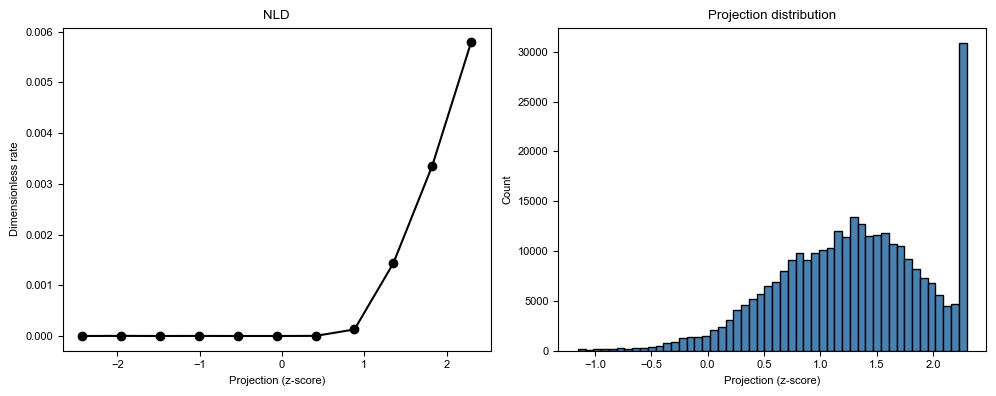

In [8]:
print(f"bin_mean range:     {bin_mean.min():.4f} to {bin_mean.max():.4f}")
print(f"bin_max range:      {bin_max.min():.4f} to {bin_max.max():.4f}")
print(f"bin_fwdModel range: {bin_fwdModel.min():.4f} to {bin_fwdModel.max():.4f}")
print(f"nld_fwdModel range: {nld_fwdModel.min():.4f} to {nld_fwdModel.max():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(bin_fwdModel, nld_fwdModel, 'o-', color='black')
ax[0].set_title('NLD')
ax[0].set_xlabel('Projection (z-score)')
ax[0].set_ylabel('Dimensionless rate')

ax[1].hist(df_proj['proj'], bins=50, color='steelblue', edgecolor='black')
ax[1].set_title('Projection distribution')
ax[1].set_xlabel('Projection (z-score)')
ax[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

In [9]:
n_clipped = np.sum(df_proj['proj'] == bin_fwdModel.max())
pct_clipped = 100 * n_clipped / len(df_proj)
print(f'samples clipped to upper bound: {n_clipped} ({pct_clipped:.1f}%)')

samples clipped to upper bound: 26651 (8.9%)


In [10]:
print(f'mean firing rate from WN: {savedModel[7]:.4f}')

mean firing rate from WN: 6.1833


In [ ]:
#def fit_nld_function(bins, values):
#     # converts discrete nld to smoothened function which can be used for prediction
    
#     import numpy as np
#     from scipy.ndimage import gaussian_filter1d
#     from scipy.interpolate import UnivariateSpline
# #     from scipy.interpolate import PchipInterpolator

#     # x: bin centers (projection values)
#     # y: spike probability per bin
#     x = np.array(bins[:-1])
#     y = np.array(values)

#     # --- Step 1: Sort (important for spline) ---
#     idx = np.argsort(x)
#     x = x[idx]
#     y = y[idx]

#     # --- Step 2: Smooth the discrete NLD ---
#     y_smooth = gaussian_filter1d(y, sigma=1.5)  
#     # sigma controls smoothing

#     # --- Step 3: Fit spline ---
#     spline = UnivariateSpline(x, y_smooth, s=0.001) # default cubic spline
#     # s = smoothing factor (smaller = closer fit)
    
#     # Monotonic spline
# #     pchip = PchipInterpolator(x, y_smooth) # piecewise cubic spline
    
#     return(spline)
# #     # --- Step 4: Predict on new inputs ---
# #     x_new = np.linspace(min(x), max(x), 500)
# #     y_pred = spline(x_new)